# 03 — Visualisations et insights

Prérequis : `python batch/batch_analysis.py` a été exécuté (tables `batch_*`). Les PNG sont enregistrés dans `outputs/figures/` pour les slides.

In [1]:
import sys, json
sys.path.insert(0, "/home/jovyan/work")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from common import config

engine = create_engine(config.SQLALCHEMY_URL)
q = lambda sql: pd.read_sql(sql, engine)

# Palette : positif = bleu, négatif = orange (paire distinguable par les daltoniens)
COLORS = {"positive": "#2a78d6", "negative": "#eb6834"}
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "grid.color": "#e6e6e6", "axes.titleweight": "bold"})
FIG_DIR = config.OUTPUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()


## 1. Répartition globale du sentiment

,sentiment,nb_toots,pct,avg_score_pos
0,negative,318,34.01,0.170
1,positive,617,65.99,0.856


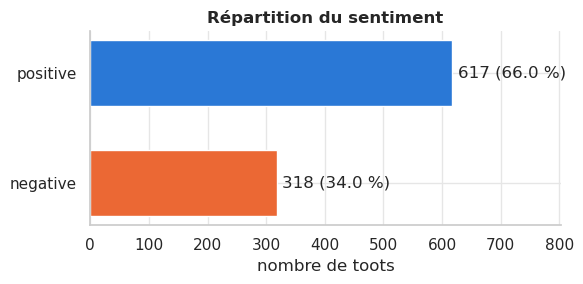

In [2]:
g = q("SELECT * FROM batch_sentiment_global")
display(g)
plt.figure(figsize=(6, 3))
bars = plt.barh(g.sentiment, g.nb_toots, color=[COLORS[x] for x in g.sentiment], height=0.6)
plt.bar_label(bars, labels=[f"{n:,} ({p:.1f} %)" for n, p in zip(g.nb_toots, g.pct)], padding=4)
plt.xlim(0, g.nb_toots.max() * 1.3)
plt.xlabel("nombre de toots"); plt.ylabel(""); plt.title("Répartition du sentiment")
savefig("01_sentiment_global")

**Insight :** _à compléter (ex. « X % des toots anglophones sont classés positifs »)._

## 2. Volume de toots dans le temps

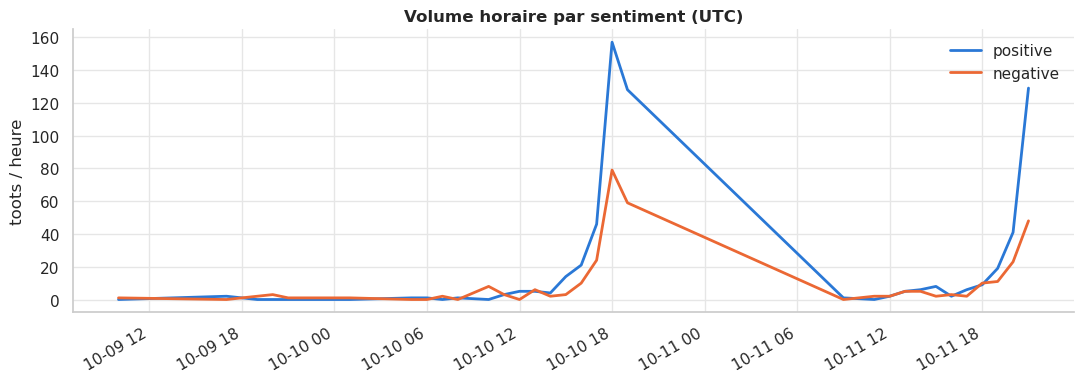

In [3]:
h = q("SELECT * FROM batch_hourly ORDER BY hour")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(h.hour, h.nb_positive, color=COLORS["positive"], lw=2, label="positive")
ax.plot(h.hour, h.nb_negative, color=COLORS["negative"], lw=2, label="negative")
ax.set_ylabel("toots / heure"); ax.set_title("Volume horaire par sentiment (UTC)"); ax.legend(frameon=False)
fig.autofmt_xdate()
savefig("02_volume_horaire")

## 3. Évolution du sentiment (fenêtres streaming de 5 min)

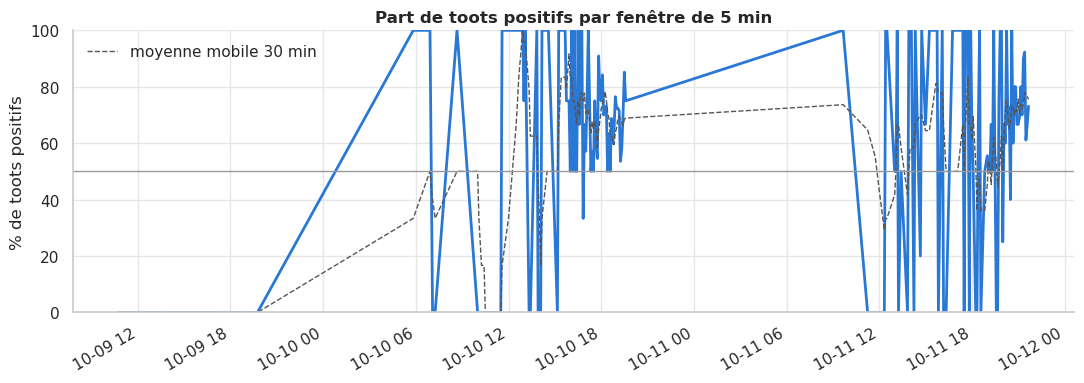

In [4]:
w = q("SELECT window_start, sentiment, SUM(nb_toots) AS nb FROM sentiment_window GROUP BY 1, 2 ORDER BY 1")
p = w.pivot(index="window_start", columns="sentiment", values="nb").fillna(0)
p["pct_positive"] = 100 * p.get("positive", 0) / p.sum(axis=1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(p.index, p.pct_positive, color=COLORS["positive"], lw=2)
ax.plot(p.index, p.pct_positive.rolling(6, min_periods=1).mean(), color="#555", lw=1, ls="--", label="moyenne mobile 30 min")
ax.axhline(50, color="#999", lw=1)
ax.set_ylabel("% de toots positifs"); ax.set_ylim(0, 100); ax.legend(frameon=False)
ax.set_title("Part de toots positifs par fenêtre de 5 min"); fig.autofmt_xdate()
savefig("03_sentiment_fenetres")

## 4. Top 15 hashtags

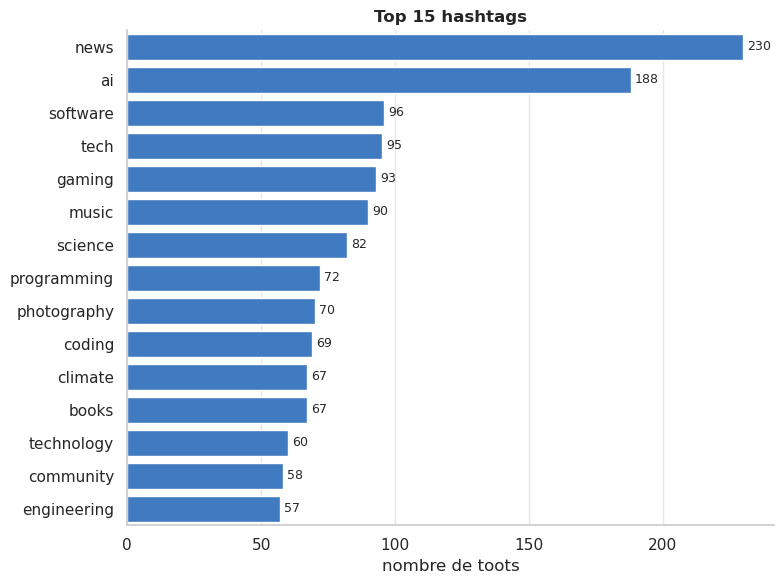

In [5]:
t = q("SELECT * FROM batch_top_hashtags ORDER BY nb_toots DESC LIMIT 15")
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=t, y="hashtag", x="nb_toots", color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%d", padding=3, fontsize=9)
plt.xlabel("nombre de toots"); plt.ylabel(""); plt.title("Top 15 hashtags")
savefig("04_top_hashtags")

## 5. Sentiment par hashtag

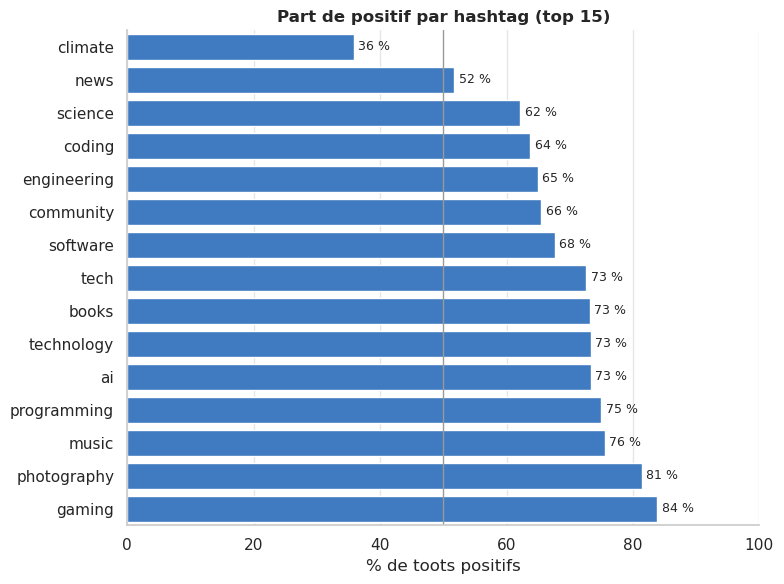

In [6]:
t2 = t.sort_values("pct_positive")
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=t2, y="hashtag", x="pct_positive", color="#2a78d6")
ax.axvline(50, color="#999", lw=1)
ax.bar_label(ax.containers[0], fmt="%.0f %%", padding=3, fontsize=9)
plt.xlim(0, 100); plt.xlabel("% de toots positifs"); plt.ylabel(""); plt.title("Part de positif par hashtag (top 15)")
savefig("05_sentiment_par_hashtag")

## 6. Heatmap d'activité (jour × heure, UTC)

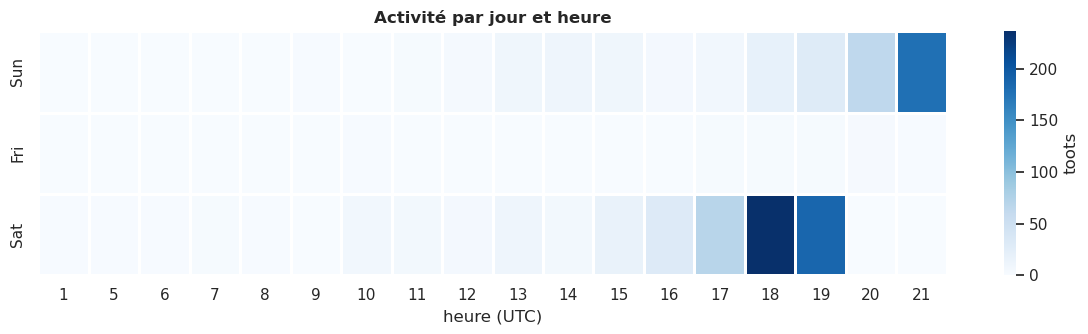

In [7]:
a = q("SELECT * FROM batch_activity")
order = a.drop_duplicates("day_num").sort_values("day_num").day.tolist()
hm = a.pivot(index="day", columns="hour", values="count").reindex(order).fillna(0)
plt.figure(figsize=(12, 3.5))
sns.heatmap(hm, cmap="Blues", linewidths=1, linecolor="white", cbar_kws={"label": "toots"})
plt.xlabel("heure (UTC)"); plt.ylabel(""); plt.title("Activité par jour et heure")
savefig("06_heatmap_activite")

## 7. Engagement selon le sentiment

,sentiment,avg_reblogs,avg_favourites,avg_replies,avg_engagement,avg_words,avg_followers
0,negative,1.09,0.46,0.08,1.62,98.6,1189.0
1,positive,1.30,0.78,0.07,2.15,58.5,768.0


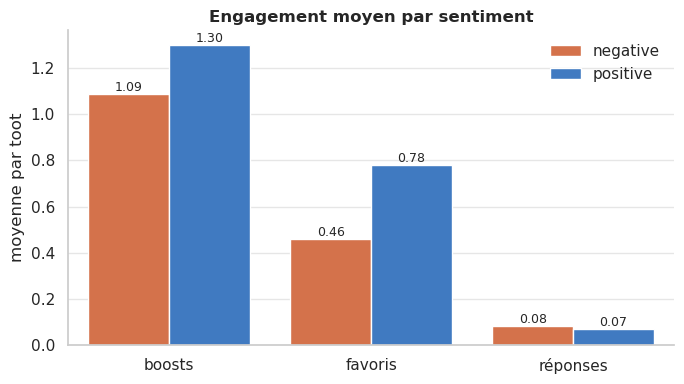

In [8]:
e = q("SELECT * FROM batch_engagement")
display(e)
m = e.melt(id_vars="sentiment", value_vars=["avg_reblogs", "avg_favourites", "avg_replies"])
m["variable"] = m.variable.map({"avg_reblogs": "boosts", "avg_favourites": "favoris", "avg_replies": "réponses"})
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=m, x="variable", y="value", hue="sentiment", palette=COLORS)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.xlabel(""); plt.ylabel("moyenne par toot"); plt.title("Engagement moyen par sentiment"); plt.legend(frameon=False)
savefig("07_engagement")

In [9]:
c = q("SELECT * FROM batch_correlation")
print(f"Corrélation engagement / score positif : {c.value[0]:.3f} sur {c.nb_toots[0]:,} toots")

Corrélation engagement / score positif : 0.006 sur 935 toots


## 8. Distribution du score de confiance

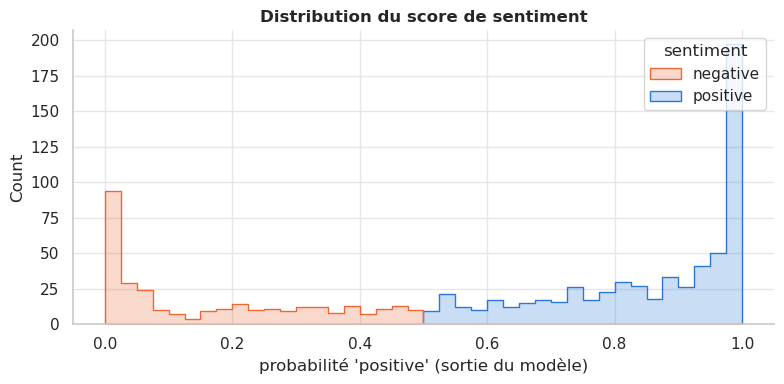

In [10]:
s = q("SELECT score_pos, sentiment FROM toots")
plt.figure(figsize=(8, 4))
sns.histplot(data=s, x="score_pos", hue="sentiment", palette=COLORS, bins=40, element="step")
plt.xlabel("probabilité 'positive' (sortie du modèle)"); plt.title("Distribution du score de sentiment")
savefig("08_distribution_score")

## Synthèse des insights
1. _…_
2. _…_
3. _…_

(Ces 3 phrases seront traduites en japonais pour la soutenance.)